In [211]:
### Import Statements

import numpy as np
import math as m
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation

In [212]:
### Define Matrix Dimensions and Size
n = 50
nt = 400
dt = 0.05

x_min = -6
x_max = 10

# Create an empty matrix
Z = np.zeros((nt,n))                       # Column Height
X = np.linspace(x_min, x_max, n)           # Column Position
V = np.zeros((nt,n))                       # Column Velocity
A = np.zeros((nt,n))                       # Column Acceleration
    


# Define the initial array
#for i in range(len(Z[0])):
#    Z[0][i] = (np.sin(X[i]))

# Log Wave
#for i in range(len(Z[0])):
#    Z[0][i] = (m.log(X[i]))

# Gaussian Curve
for i in range(len(Z[0])):
    Z[0][i] = (m.exp(1))**(-1 * ((X[i] - 3)**2))


# Fixed Boundary Points
Z[0][0] = 0
Z[0][n-1] = 0

# Local Wave Equation Variables
dx = X[1] - X[0]
c = 1.0


print("Simulation Information:")
print("_________________________________________________________________")
print(f"Number of Columns: {n}")
print(f"Number of Time Steps: {nt}")
print(f"Length of Time Step: {dt}")
print(f"Range of X-Domain: {x_min} -> {x_max}")
print()
print(f"Stability (check if ≤ 1.0): {c * (dt/dx)}")

print("_________________________________________________________________")



Simulation Information:
_________________________________________________________________
Number of Columns: 50
Number of Time Steps: 400
Length of Time Step: 0.05
Range of X-Domain: -6 -> 10

Stability (check if ≤ 1.0): 0.15312499999999984
_________________________________________________________________


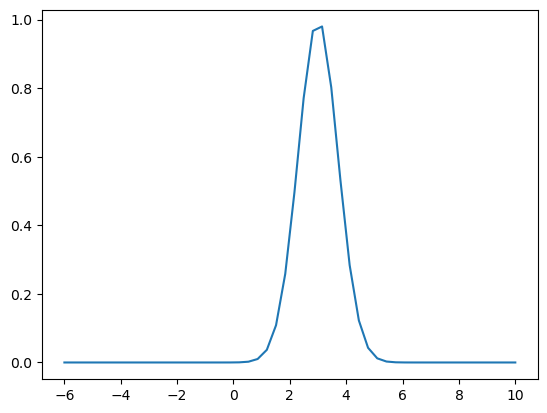

In [213]:
plt.plot(X, Z[0])

In [214]:
### Define Model Physics


for t in range(nt):
    S = np.zeros(n, dtype=float)
     
    for i in range(n):
        for j in range(n):
            if i != j:
                if X[j]-X[i] < 0:
                    S[i] += ((Z[t][j]-Z[t][i]) * -1) / (X[j]-X[i])
                else:
                    S[i] += (Z[t][j]-Z[t][i]) / (X[j]-X[i])
    
    for i in range(1, n-1):
        if t+1 >= nt:
            break
        else:
            A[t+1][i] = c**2 * (Z[t][i+1] - 2*Z[t][i] + Z[t][i-1]) / dx**2            
            V[t+1][i] = V[t][i] + (A[t+1][i] * dt)
            Z[t+1][i] = Z[t][i] + (V[t+1][i] * dt)


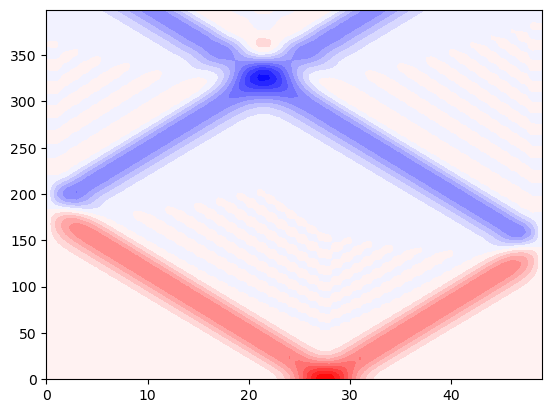

In [215]:
plt.contourf(Z, 20, cmap='bwr')


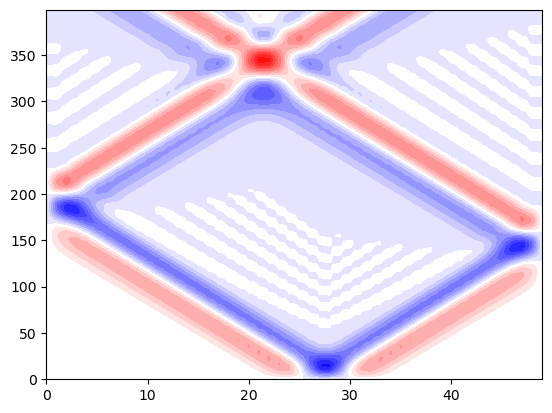

In [216]:
plt.contourf(V, 20, cmap='bwr')

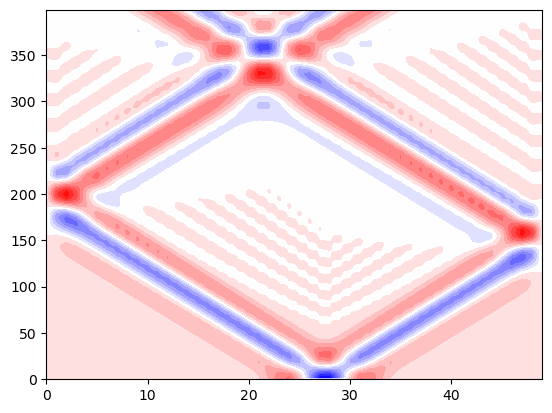

In [217]:
plt.contourf(A, 20, cmap='bwr')

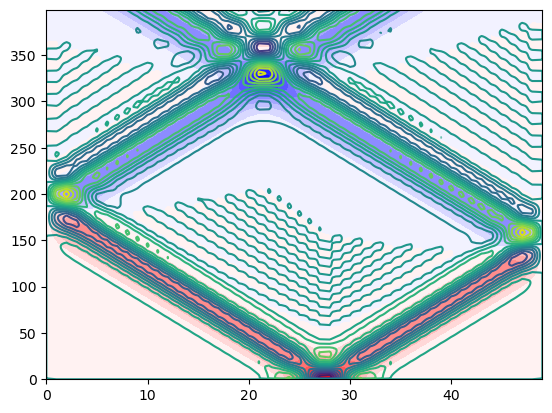

In [218]:
plt.contourf(Z, 20, cmap='bwr')
plt.contour(A, 20)


In [219]:
# Buffer Cell for Safety

In [220]:
# Buffer Cell for Safety

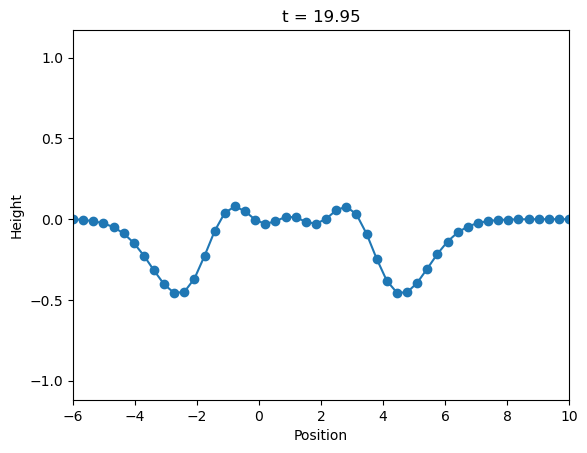

In [221]:
### Animate the frames

fig, ax = plt.subplots()
line, = ax.plot(X, Z[0], 'o-')            # 'o-' shows the individual columns

ax.set_xlim(x_min, x_max)
pad = 0.1 * (Z.max() - Z.min())
ax.set_ylim(Z.min() - pad, Z.max() + pad)  # fixed limits so the axes don't jump
ax.set_xlabel("Position")
ax.set_ylabel("Height")
title = ax.set_title("t = 0.00")

def update(frame):
    line.set_ydata(Z[frame])
    title.set_text(f"t = {frame * dt:.2f}")
    return line, title

ani = FuncAnimation(fig, update, frames=nt, interval=50, blit=False)
ani.save("Gaussian_Init_3.gif", writer="pillow", fps=10)

plt.show()